# slots_v1:把物体槽加到题目的名字 token 上

**做法**(做法 1):题目里每个物体名,先用冻结的 dino.txt + 点提示头(box05)算出 4 个候选 3D 位置和置信度(物体槽);`SlotEncoder` 把它变成一个向量,加到题目中该名字的 token 上,再进 Llama predictor。其余设置与 hardneg_v1 相同(6870 步,3 张卡,4 h 05 min)。

**对照**(都用同一个 checkpoint):

| 名称 | 场景 token | 槽 |
|---|---|---|
| real | 本题的 | 本题的 |
| shuffled / zero | 别的题的 / 全零 | 本题的 |
| slots_swapped | 本题的 | 别的题的 |
| slots_none | 本题的 | 不给 |
| all_shuffled | 别的题的 | 别的题的 |

## 结论

- **模型没有用槽里的位置**。real 和 slots_swapped 在所有题型上相同(留出集 47.4 对 47.5,VSI-Bench 33.4 对 33.8)。
- **模型只用了"这里有个槽向量"这件事**。不给槽时留出集长答案从 47.4 掉到 28.7,低于随机(29.9);换成别的题的槽不掉。也就是槽向量被学成了物体名的标记,内容被忽略。
- **VSI-Bench 没有提升**:33.4,hardneg_v1 是 33.7。方向题和距离题仍在随机水平附近,而按规则直接用槽算答案是 65–78% 和 44%。
- **留出集长答案略升**(46.7 → 47.4),但换槽后一样,所以不是槽的位置带来的。
- **两处变差**:留出集短答案 41.9 → 33.9,VSI-Bench 路径规划 33.3 → 23.3(debiased 34.9 → 17.5)。原因未查。
- 每个题型只有 100–1000 题,3 个点以内的差别不算数。

## 下一步(未做)

1. 先查训练后的 `SlotEncoder` 输出是否随位置变化(若几乎是常数,说明梯度没把位置信息用起来)。
2. 槽信息很可能要以模型绕不开的方式给:做法 2(槽作为单独 token,带点提示头特征)或在槽上加一个直接依赖位置的训练目标。

In [1]:
import json
import pandas as pd
s = json.load(open("../results/eval_final.json"))
h = json.load(open("../../hardneg_v1/results/eval_final.json"))
MODES = ["real", "shuffled", "zero", "slots_swapped", "slots_none", "all_shuffled"]
acc = lambda v: None if v is None else 100 * (v["acc"] if isinstance(v, dict) else v)

def table(ds, keep=lambda k: True):
    rows = {}
    for k, v in s["real"][ds].items():
        if not keep(k):
            continue
        row = {"题数": v.get("rows") if isinstance(v, dict) else None,
               "随机": acc({"acc": v["chance"]}) if isinstance(v, dict) else None,
               "hardneg_v1 real": acc(h["real"][ds].get(k)), "hardneg_v1 shuffled": acc(h["shuffled"][ds].get(k))}
        row.update({m: acc(s[m][ds][k]) for m in MODES})
        rows[k] = row
    return pd.DataFrame(rows).T.dropna(axis=1, how="all").astype(float).round(1)
print("checkpoint", s["checkpoint"], "step", s["step"])

checkpoint experiments/slots_v1/ckpt/final.pt step 6870


## 1. 留出集,长答案(训练时的答案格式)

In [2]:
table("holdout", lambda k: k.startswith("long/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
long/all,6786.0,29.9,46.7,44.1,47.4,43.9,44.3,47.5,28.7,43.8
long/spar/appearance_order,1000.0,25.0,37.7,28.8,40.8,33.3,34.1,40.5,22.6,33.3
long/spar/spatial_imagination_oc_video_hard,1000.0,31.2,44.8,43.7,41.8,41.8,41.9,42.6,42.4,42.2
long/spar/spatial_imagination_oo_video_hard,1000.0,13.3,23.6,23.3,24.3,22.5,23.1,24.1,22.9,22.0
long/vsi590k/appearance_order,632.0,25.0,45.7,40.8,47.5,41.3,40.7,47.6,16.9,40.0
long/vsi590k/relative_count,154.0,33.3,55.2,45.5,56.5,40.9,37.0,55.8,27.3,42.9
long/vsi590k/relative_direction_object,1000.0,37.3,46.1,45.8,45.7,43.5,44.4,45.7,41.0,43.2
long/vsi590k/relative_distance_object,1000.0,25.0,42.5,41.4,46.0,40.4,41.1,46.0,25.4,40.7
long/vsi590k/relative_size_object,1000.0,50.0,84.7,83.6,84.5,84.3,84.9,84.5,25.8,84.1


real = slots_swapped;slots_none 在带物体名的题型上掉到随机以下;SPAR 的两个 `spatial_imagination_*` 题型不受影响。

## 2. 留出集,短答案

In [3]:
table("holdout", lambda k: k.startswith("short/"))

,题数,随机,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
short/all,3786.0,35.2,41.9,40.8,33.9,33.9,36.7,34.2,33.9,34.4
short/vsi590k/appearance_order,632.0,25.0,42.6,36.2,35.8,32.1,31.2,36.1,21.0,33.1
short/vsi590k/relative_count,154.0,33.3,21.4,21.4,25.3,29.2,31.2,30.5,18.8,31.8
short/vsi590k/relative_direction_object,1000.0,37.3,46.5,45.6,26.8,31.1,40.0,26.4,36.1,30.9
short/vsi590k/relative_distance_object,1000.0,25.0,30.9,31.0,24.6,24.7,24.3,25.4,26.4,25.7
short/vsi590k/relative_size_object,1000.0,50.0,50.9,51.6,50.6,47.7,50.2,50.3,49.6,47.8


比 hardneg_v1 低 8 个点,方向题从 46.5 掉到 26.8。

## 3. VSI-Bench test

In [4]:
table("vsibench_test_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,33.7,33.2,33.4,32.4,33.8,33.8,27.2,32.6
type/obj_appearance_order,40.9,40.1,41.4,40.6,31.2,40.5,27.8,39.8
type/object_rel_direction_easy,50.8,50.0,51.7,48.3,49.2,53.3,50.0,52.5
type/object_rel_direction_hard,27.3,27.7,26.4,27.3,43.7,29.0,10.0,26.0
type/object_rel_direction_medium,29.6,32.1,34.6,33.7,44.4,35.0,44.0,35.4
type/object_rel_distance,26.2,24.9,24.3,22.7,26.2,25.0,21.9,23.2
type/route_planning,33.3,31.1,23.3,23.3,23.3,23.3,22.2,22.2


参考:按规则直接用槽算答案(`experiments/slot_vsibench_check`):方向 easy 77.5 / medium 70.4 / hard 64.9,相对距离 44.4。

## 4. VSI-Bench debiased

In [5]:
table("vsibench_debiased_posed_f8")

,hardneg_v1 real,hardneg_v1 shuffled,real,shuffled,zero,slots_swapped,slots_none,all_shuffled
all,35.0,34.3,30.2,30.9,26.6,30.1,29.5,30.2
type/obj_appearance_order,36.2,36.8,33.3,32.1,25.2,33.3,30.2,32.1
type/object_rel_direction_easy,51.3,50.4,50.4,45.3,47.9,50.4,51.3,47.9
type/object_rel_direction_hard,23.9,19.4,11.9,22.4,20.9,13.4,26.9,22.4
type/object_rel_direction_medium,45.9,43.2,37.8,40.5,21.6,35.1,24.3,35.1
type/object_rel_distance,25.8,26.3,22.5,25.8,22.0,22.0,21.5,23.0
type/route_planning,34.9,28.6,17.5,19.0,19.0,17.5,17.5,17.5


## 5. 训练曲线

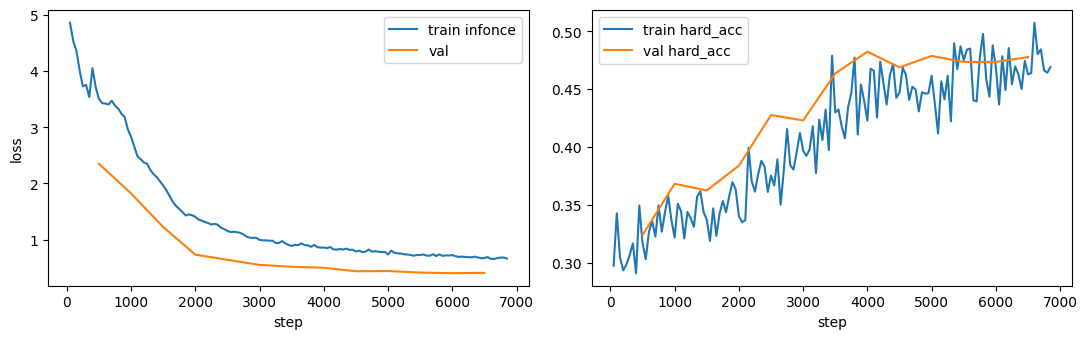

In [6]:
import matplotlib.pyplot as plt
load = lambda p: pd.DataFrame([json.loads(l) for l in open(p)])
t, n = load("../results/train_log.jsonl"), load("../results/hardneg_log.jsonl")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
a = t.dropna(subset=["loss"]); ax[0].plot(a.step, a.loss, label="train infonce")
if "val_loss" in t: b = t.dropna(subset=["val_loss"]); ax[0].plot(b.step, b.val_loss, label="val")
ax[0].set_xlabel("step"); ax[0].set_ylabel("loss"); ax[0].legend()
a = n.dropna(subset=["hard_acc"]); ax[1].plot(a.step, a.hard_acc, label="train hard_acc")
if "val_hard_acc" in n: b = n.dropna(subset=["val_hard_acc"]); ax[1].plot(b.step, b.val_hard_acc, label="val hard_acc")
ax[1].set_xlabel("step"); ax[1].legend(); plt.tight_layout()

## 6. 槽数据

In [7]:
import glob
pd.DataFrame({p.split("/")[-1].replace(".stats.json", ""): {k: v for k, v in json.load(open(p)).items()
              if k in ("rows", "rows_with_slots", "object_names")} | {"conf 中位数": json.load(open(p))["top_conf_quantiles"]["50%"]}
              for p in sorted(glob.glob("../results/*.stats.json"))}).T

,rows,rows_with_slots,object_names,conf 中位数
holdout_f8.jsonl,6786.0,6786.0,2732.0,4.76
train_f8.jsonl.part0,164863.0,155264.0,2732.0,4.68
train_f8.jsonl.part1,164551.0,155036.0,2732.0,4.68
train_f8.jsonl.part2,164899.0,155283.0,2732.0,4.68
train_f8.jsonl.part3,164205.0,154654.0,2732.0,4.68
vsibench_debiased_posed_f8.jsonl,811.0,811.0,2732.0,4.83
vsibench_test_posed_f8.jsonl,1845.0,1845.0,2732.0,4.87
